# 1 - Introdução - Entendendo o problema de negócio do Cliente

O Problema tem como o objetivo em prever o diagnóstico positivo "P" ou negativo "N" para o hipertiroidismo com base nos parâmetros:
- age: Idade;
- Sex: sexo;
- on thyroxine: uso de tiroxina;
- query on thyroxyne: suspeita de uso de tiroxina;
- on antithyroid medication: em uso de medicação antitireoidiana;
- sick: doente;
- pregnant: grávida;
- thyroid surgery: cirurgia de tireóide;
- I131 treatment: tratamento com iodo-131;
- query hypothyroid: suspeita de hipotireoidismo;
- query hyperthyroid: suspeita de hipertireoidismo;
- lithium: lítio;
- goitre: bócio;
- tumor: tumor;
- hypopituitary: hipopituitarismo;
- psych: condição psiquiátrica;
- TSH measured:	TSH medido
- TSH:	TSH (hormônio estimulante da tireoide)
- T3 measured:	T3 medido
- T3:	T3 (tri-iodotironina)
- TT4 measured:	T4 total medido
- TT4:	T4 total (tiroxina total)
- T4U measured:	T4U medido
- T4U:	captação de T4 (T4 uptake)
- FTI measured:	FTI medido
- FTI:	índice de tiroxina livre (Free Thyroxine Index)
- TBG measured:	TBG medida
- TBG:	TBG (globulina ligadora de tiroxina)
- referral source:	origem do encaminhamento
- binaryClass:	classe binária

Devemos utilizar modelos robustos para chegar à uma boa precisão e diminuir falsos negativos. Para isso, os modelos robustos que serão utilizados serão: XGBoos, SVM e Random Forest. Será feito o treinamento inicialmente sem a ajuste de hiperparâmetros, e em seguida, com hiperparâmetros.

# 2 - Importação das bibliotecas e dos dados

In [265]:
# Bibliotecas para manipulação dos dados
import pandas as pd
import numpy as np

# Bibliotecas para visualização dos dados
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier

# Bibliotecas para pré-processamento e divisão dos dados
from sklearn.preprocessing import StandardScaler, LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Bibliotecas para os modelos de machine learning
import xgboost as xgb
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Bibliotecas para métricas de avaliação
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve

# Biblioeteca para contagem de caracteres especiais
import re

In [266]:
pd.set_option('display.max_columns', None)

In [267]:
dados = pd.read_csv('../data/hypothyroid.csv')
dados

,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,query hyperthyroid,lithium,goitre,tumor,hypopituitary,psych,TSH measured,TSH,T3 measured,T3,TT4 measured,TT4,T4U measured,T4U,FTI measured,FTI,TBG measured,TBG,referral source,binaryClass
0,41,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,1.3,t,2.5,t,125,t,1.14,t,109,f,?,SVHC,P
1,23,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,4.1,t,2,t,102,f,?,f,?,f,?,other,P
2,46,M,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.98,f,?,t,109,t,0.91,t,120,f,?,other,P
3,70,F,t,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.16,t,1.9,t,175,f,?,f,?,f,?,other,P
4,70,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.72,t,1.2,t,61,t,0.87,t,70,f,?,SVI,P
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3767,30,F,f,f,f,f,f,f,f,f,f,f,f,t,f,f,f,?,f,?,f,?,f,?,f,?,f,?,other,P
3768,68,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,1,t,2.1,t,124,t,1.08,t,114,f,?,SVI,P
3769,74,F,f,f,f,f,f,f,f,f,t,f,f,f,f,f,t,5.1,t,1.8,t,112,t,1.07,t,105,f,?,other,P
3770,72,M,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.7,t,2,t,82,t,0.94,t,87,f,?,SVI,P


Temos um total de 3772 registros para 29 features, iremos analisar os dados faltantes e alguns dados estatísticos a seguir. Na colina FTI e TBG, temos o caracter "?", tal caracter será tratado como valor nulo por não representar uma respota para features. Os dados serão recarregados considerando '?' como NaN.


In [268]:
# Importando base de dados considerando '?' como Nan
dados = pd.read_csv('../data/hypothyroid.csv', na_values=['?'])
dados

,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,query hyperthyroid,lithium,goitre,tumor,hypopituitary,psych,TSH measured,TSH,T3 measured,T3,TT4 measured,TT4,T4U measured,T4U,FTI measured,FTI,TBG measured,TBG,referral source,binaryClass
0,41.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,1.30,t,2.5,t,125.0,t,1.14,t,109.0,f,NaN,SVHC,P
1,23.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,4.10,t,2.0,t,102.0,f,NaN,f,NaN,f,NaN,other,P
2,46.0,M,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.98,f,NaN,t,109.0,t,0.91,t,120.0,f,NaN,other,P
3,70.0,F,t,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.16,t,1.9,t,175.0,f,NaN,f,NaN,f,NaN,other,P
4,70.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.72,t,1.2,t,61.0,t,0.87,t,70.0,f,NaN,SVI,P
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3767,30.0,F,f,f,f,f,f,f,f,f,f,f,f,t,f,f,f,NaN,f,NaN,f,NaN,f,NaN,f,NaN,f,NaN,other,P
3768,68.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,1.00,t,2.1,t,124.0,t,1.08,t,114.0,f,NaN,SVI,P
3769,74.0,F,f,f,f,f,f,f,f,f,t,f,f,f,f,f,t,5.10,t,1.8,t,112.0,t,1.07,t,105.0,f,NaN,other,P
3770,72.0,M,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.70,t,2.0,t,82.0,t,0.94,t,87.0,f,NaN,SVI,P


# 3 - Exploração dos dados

In [269]:
dados.info()

<class 'pandas.DataFrame'>
RangeIndex: 3772 entries, 0 to 3771
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age                        3771 non-null   float64
 1   sex                        3622 non-null   str    
 2   on thyroxine               3772 non-null   str    
 3   query on thyroxine         3772 non-null   str    
 4   on antithyroid medication  3772 non-null   str    
 5   sick                       3772 non-null   str    
 6   pregnant                   3772 non-null   str    
 7   thyroid surgery            3772 non-null   str    
 8   I131 treatment             3772 non-null   str    
 9   query hypothyroid          3772 non-null   str    
 10  query hyperthyroid         3772 non-null   str    
 11  lithium                    3772 non-null   str    
 12  goitre                     3772 non-null   str    
 13  tumor                      3772 non-null   str    
 14  hyp

In [270]:
dados.describe()

,age,TSH,T3,TT4,T4U,FTI,TBG
count,3771.000000,3403.000000,3003.000000,3541.000000,3385.000000,3387.000000,0.0
mean,51.735879,5.086766,2.013500,108.319345,0.995000,110.469649,NaN
std,20.084958,24.521470,0.827434,35.604248,0.195457,33.089698,NaN
min,1.000000,0.005000,0.050000,2.000000,0.250000,2.000000,NaN
25%,36.000000,0.500000,1.600000,88.000000,0.880000,93.000000,NaN
50%,54.000000,1.400000,2.000000,103.000000,0.980000,107.000000,NaN
75%,67.000000,2.700000,2.400000,124.000000,1.080000,124.000000,NaN
max,455.000000,530.000000,10.600000,430.000000,2.320000,395.000000,NaN


In [271]:
dados[dados['age'] == 455]

,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,query hyperthyroid,lithium,goitre,tumor,hypopituitary,psych,TSH measured,TSH,T3 measured,T3,TT4 measured,TT4,T4U measured,T4U,FTI measured,FTI,TBG measured,TBG,referral source,binaryClass
1364,455.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,1.1,t,2.0,t,118.0,t,1.13,t,104.0,f,NaN,SVI,P


In [272]:
dados.nunique()

age                           93
sex                            2
on thyroxine                   2
query on thyroxine             2
on antithyroid medication      2
sick                           2
pregnant                       2
thyroid surgery                2
I131 treatment                 2
query hypothyroid              2
query hyperthyroid             2
lithium                        2
goitre                         2
tumor                          2
hypopituitary                  2
psych                          2
TSH measured                   2
TSH                          287
T3 measured                    2
T3                            69
TT4 measured                   2
TT4                          241
T4U measured                   2
T4U                          146
FTI measured                   2
FTI                          234
TBG measured                   1
TBG                            0
referral source                5
binaryClass                    2
dtype: int

É possível notar a presença de alguns valores inconsistentes como idade igual a 455 anos, e valores de outras colunas que podem ser considerados outilers. Será visto com mais detalhes na análise univariada. Em TBG measured, temos apenas uma única variável, e em TBG nenhuma, apenas valores nulos.

In [273]:
dados.isnull().sum()/len(dados) * 100

age                            0.026511
sex                            3.976670
on thyroxine                   0.000000
query on thyroxine             0.000000
on antithyroid medication      0.000000
sick                           0.000000
pregnant                       0.000000
thyroid surgery                0.000000
I131 treatment                 0.000000
query hypothyroid              0.000000
query hyperthyroid             0.000000
lithium                        0.000000
goitre                         0.000000
tumor                          0.000000
hypopituitary                  0.000000
psych                          0.000000
TSH measured                   0.000000
TSH                            9.782609
T3 measured                    0.000000
T3                            20.387063
TT4 measured                   0.000000
TT4                            6.124072
T4U measured                   0.000000
T4U                           10.259809
FTI measured                   0.000000


Analisando a quantidade de valores faltantes, serão adotados as seguintes operações:
- Remoção da coluna 'TBG', por conta da coluna ser composto 100 % de valores nulos;
- Remoção dos registros (Linhas) que contém "?" nas features 'sex' e 'age'. 3.97 % e 0.026 % respectivamente

Em seguida, será feito uma análise univariada de algumas features para analisar possíveis outliers para decidir como serão tratados os valores faltantes.

## 3.1 Análise Univariada

BoxPlot das features: age, TSH, T3, TT4, T4U, FTI, TBG

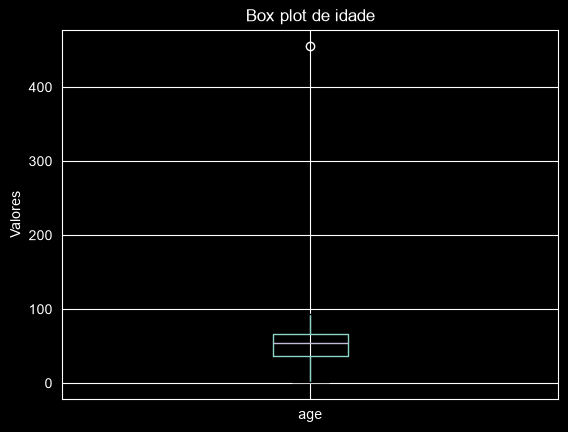

In [274]:
# BoxPlot Idade

dados.boxplot(column='age')
plt.title('Box plot de idade')
plt.ylabel('Valores')
plt.show()

Evidência do outlier de idade = 455
Decisão: Remover registro

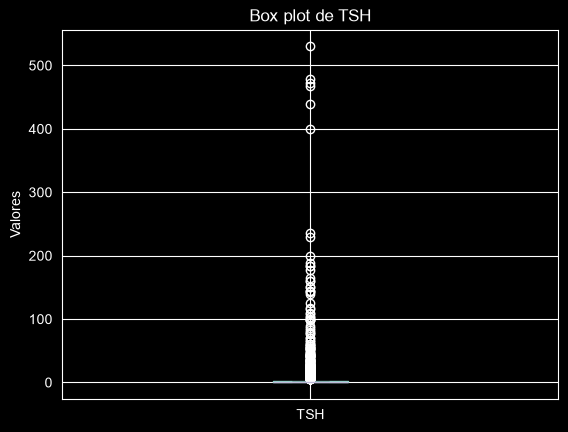

In [275]:
# BoxPlot TSH

dados.boxplot(column='TSH')
plt.title('Box plot de TSH')
plt.ylabel('Valores')
plt.show()

In [276]:
# Analisando quantidade de valores outliers (75% + std)
std = 24.52
Q3 = 2.7

quantidade = (dados['TSH'] > (Q3+std)).sum()
relacao = (dados['TSH'] > (Q3+std)).sum()/len(dados) * 100

quantidade_maior_400 = (dados['TSH'] > 400).sum()
relacao_maior_400 = (dados['TSH'] > 400).sum()/len(dados) * 100

print('quantidade outlier de TSH = {}'.format(quantidade))
print('relacao outlier de TSH = {}'.format(relacao))

print('quantidade acima de 400 de TSH = {}'.format(quantidade_maior_400))
print('relacao acima de 400 de TSH = {}'.format(relacao_maior_400))

quantidade outlier de TSH = 95
relacao outlier de TSH = 2.518557794273595
quantidade acima de 400 de TSH = 5
relacao acima de 400 de TSH = 0.1325556733828208


Evidência de 95 (2.51 % do total dos dados) valores de outlier
Decisão: Remover registros com valores outliers

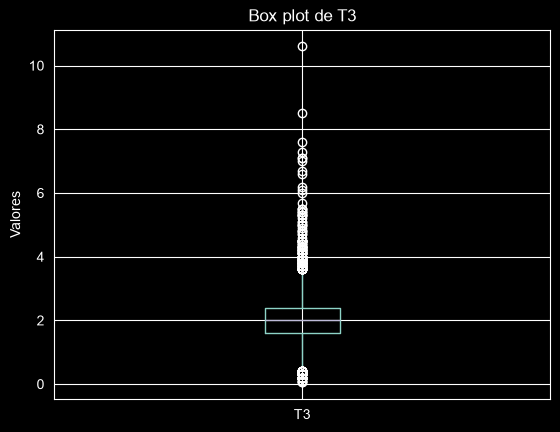

In [277]:
# BoxPlot T3

dados.boxplot(column='T3')
plt.title('Box plot de T3')
plt.ylabel('Valores')
plt.show()

In [278]:
# Analisando quantidade de valores outliers (75% + std)

std = 0.827
Q1 = 1.6
Q3 = 2.4

quantidade_sup = (dados['T3'] > (Q3+std)).sum()
relacao_sup = (dados['T3'] > (Q3+std)).sum()/len(dados) * 100

quantidade_inf = (dados['T3'] < (Q1-std)).sum()
relacao_inf = (dados['T3'] < (Q1-std)).sum()/len(dados) * 100

quantidade_maior_7 = (dados['T3'] > 7).sum()
relacao_maior_7 = (dados['T3'] > 7).sum()/len(dados) * 100

print('quantidade_sup de T3 = {}'.format(quantidade_sup))
print('relacao_sup de T3 = {}'.format(relacao_sup))

print('quantidade_inf de T3 = {}'.format(quantidade_inf))
print('relacao_inf de T3 = {}'.format(relacao_inf))

print('quantidade acima de 7 de T3 = {}'.format(quantidade_maior_7))
print('relacao acima de 7 de T3 = {}'.format(relacao_maior_7))

quantidade_sup de T3 = 169
relacao_sup de T3 = 4.480381760339343
quantidade_inf de T3 = 132
relacao_inf de T3 = 3.4994697773064685
quantidade acima de 7 de T3 = 6
relacao acima de 7 de T3 = 0.15906680805938495


Decisão: remover os valores acima de 7, a diferença percentual dos outiliers superior e inferior é menor que 1. Há um "equilíbrio"

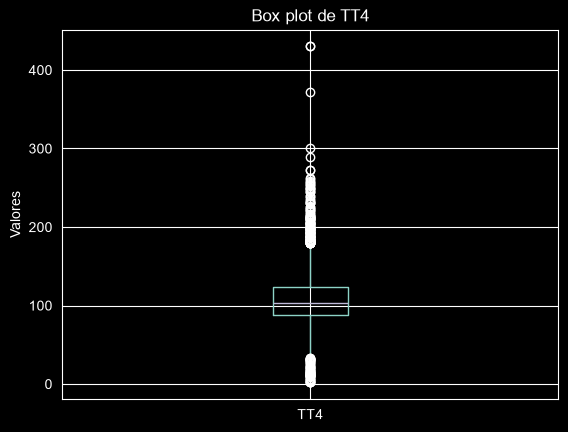

In [279]:
# BoxPlot TT4

dados.boxplot(column='TT4')
plt.title('Box plot de TT4')
plt.ylabel('Valores')
plt.show()

In [280]:
# Analisando quantidade de valores outliers (75% + std)

std = 35.60
Q1 = 88
Q3 = 124
coluna = 'TT4'
valor_selecionado = 200

quantidade_sup = (dados[coluna] > (Q3+std)).sum()
relacao_sup = (dados[coluna] > (Q3+std)).sum()/len(dados) * 100

quantidade_inf = (dados[coluna] < (Q1-std)).sum()
relacao_inf = (dados[coluna] < (Q1-std)).sum()/len(dados) * 100

quantidade_maior_selecionado = (dados[coluna] >= valor_selecionado).sum()
relacao_maior_selecionado = (dados[coluna] >= valor_selecionado).sum()/len(dados) * 100

print('quantidade_sup de {} = {}'.format(coluna, quantidade_sup))
print('relacao_sup de {} = {}'.format(coluna, relacao_sup))

print('quantidade_inf de {} = {}'.format(coluna, quantidade_inf))
print('relacao_inf de {} = {}'.format(coluna, relacao_inf))

print('quantidade a partir de {} = {}'.format(valor_selecionado, quantidade_maior_selecionado))
print('relacao partir de {}  = {}'.format(valor_selecionado, relacao_maior_selecionado))

quantidade_sup de TT4 = 262
relacao_sup de TT4 = 6.945917285259809
quantidade_inf de TT4 = 112
relacao_inf de TT4 = 2.9692470837751856
quantidade a partir de 200 = 69
relacao partir de 200  = 1.8292682926829267


Decisão: Retirar valores acima de 200, e manter os outros valores de Outliers

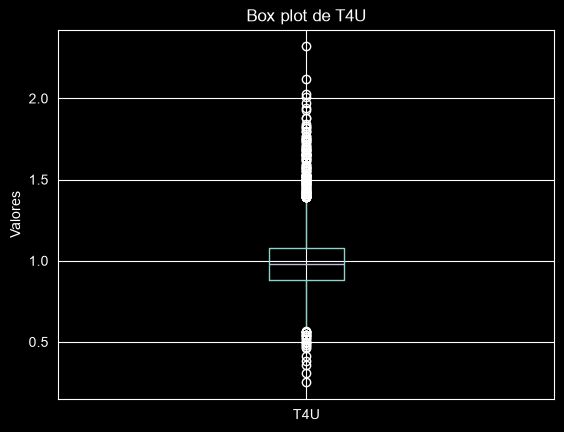

In [281]:
# BoxPlot TT4

dados.boxplot(column='T4U')
plt.title('Box plot de T4U')
plt.ylabel('Valores')
plt.show()

In [282]:
# Analisando quantidade de valores outliers (75% + std)

std = 0.195
Q1 = 0.88
Q3 = 1.08
coluna = 'T4U'
valor_selecionado = 1.5

quantidade_sup = (dados[coluna] > (Q3+std)).sum()
relacao_sup = (dados[coluna] > (Q3+std)).sum()/len(dados) * 100

quantidade_inf = (dados[coluna] < (Q1-std)).sum()
relacao_inf = (dados[coluna] < (Q1-std)).sum()/len(dados) * 100

quantidade_maior_selecionado = (dados[coluna] >= valor_selecionado).sum()
relacao_maior_selecionado = (dados[coluna] >= valor_selecionado).sum()/len(dados) * 100

print('quantidade_sup de {} = {}'.format(coluna, quantidade_sup))
print('relacao_sup de {} = {}'.format(coluna, relacao_sup))

print('quantidade_inf de {} = {}'.format(coluna, quantidade_inf))
print('relacao_inf de {} = {}'.format(coluna, relacao_inf))

print('quantidade a partir de {} = {}'.format(valor_selecionado, quantidade_maior_selecionado))
print('relacao partir de {}  = {}'.format(valor_selecionado, relacao_maior_selecionado))

quantidade_sup de T4U = 225
relacao_sup de T4U = 5.965005302226936
quantidade_inf de T4U = 89
relacao_inf de T4U = 2.35949098621421
quantidade a partir de 1.5 = 92
relacao partir de 1.5  = 2.4390243902439024


Decisão: Retirar valores a partir de 1.5, e manter o restante dos outliers

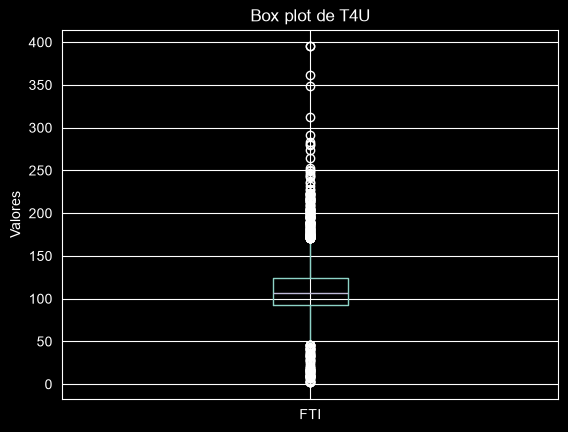

In [283]:
# BoxPlot FTI

dados.boxplot(column='FTI')
plt.title('Box plot de T4U')
plt.ylabel('Valores')
plt.show()

In [284]:
# Analisando quantidade de valores outliers (75% + std)

std = 33.089
Q1 = 93
Q3 = 124
coluna = 'FTI'
valor_selecionado = 200

quantidade_sup = (dados[coluna] > (Q3+std)).sum()
relacao_sup = (dados[coluna] > (Q3+std)).sum()/len(dados) * 100

quantidade_inf = (dados[coluna] < (Q1-std)).sum()
relacao_inf = (dados[coluna] < (Q1-std)).sum()/len(dados) * 100

quantidade_maior_selecionado = (dados[coluna] >= valor_selecionado).sum()
relacao_maior_selecionado = (dados[coluna] >= valor_selecionado).sum()/len(dados) * 100

print('quantidade_sup de {} = {}'.format(coluna, quantidade_sup))
print('relacao_sup de {} = {}'.format(coluna, relacao_sup))

print('quantidade_inf de {} = {}'.format(coluna, quantidade_inf))
print('relacao_inf de {} = {}'.format(coluna, relacao_inf))

print('quantidade a partir de {} = {}'.format(valor_selecionado, quantidade_maior_selecionado))
print('relacao partir de {}  = {}'.format(valor_selecionado, relacao_maior_selecionado))

quantidade_sup de FTI = 225
relacao_sup de FTI = 5.965005302226936
quantidade_inf de FTI = 105
relacao_inf de FTI = 2.7836691410392365
quantidade a partir de 200 = 64
relacao partir de 200  = 1.6967126193001063


Decisão: Retirar valores acima de 200 e manter o restante dos outliers

Em relação à coluna 'TBG', iremos remover toda a coluna, pois é composta 100 % por valores faltantes

Antes de realizar o processo de tratamento de outliers, será removido a coluna 'TBG' e analisaremos a matriz de correlação para ver o nível de relevância das variáveis antes do pré processamento delas. Será convertido a coluna target para categórica binária com o Label Encoder

In [285]:
label_encoder = LabelEncoder()
dados['binaryClass'] = label_encoder.fit_transform(dados['binaryClass'])
dados['binaryClass']

0       1
1       1
2       1
3       1
4       1
       ..
3767    1
3768    1
3769    1
3770    1
3771    1
Name: binaryClass, Length: 3772, dtype: int64

In [286]:
# Retirando a coluna 'TBG'
dados.drop(columns='TBG', inplace=True)

In [287]:
dados

,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,query hyperthyroid,lithium,goitre,tumor,hypopituitary,psych,TSH measured,TSH,T3 measured,T3,TT4 measured,TT4,T4U measured,T4U,FTI measured,FTI,TBG measured,referral source,binaryClass
0,41.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,1.30,t,2.5,t,125.0,t,1.14,t,109.0,f,SVHC,1
1,23.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,4.10,t,2.0,t,102.0,f,NaN,f,NaN,f,other,1
2,46.0,M,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.98,f,NaN,t,109.0,t,0.91,t,120.0,f,other,1
3,70.0,F,t,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.16,t,1.9,t,175.0,f,NaN,f,NaN,f,other,1
4,70.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.72,t,1.2,t,61.0,t,0.87,t,70.0,f,SVI,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3767,30.0,F,f,f,f,f,f,f,f,f,f,f,f,t,f,f,f,NaN,f,NaN,f,NaN,f,NaN,f,NaN,f,other,1
3768,68.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,1.00,t,2.1,t,124.0,t,1.08,t,114.0,f,SVI,1
3769,74.0,F,f,f,f,f,f,f,f,f,t,f,f,f,f,f,t,5.10,t,1.8,t,112.0,t,1.07,t,105.0,f,other,1
3770,72.0,M,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.70,t,2.0,t,82.0,t,0.94,t,87.0,f,SVI,1


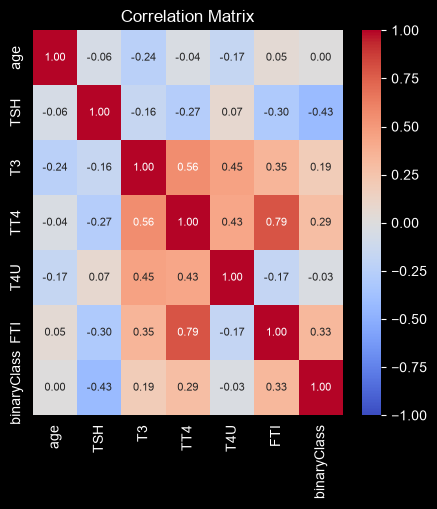

In [288]:
correlation_matrix = dados.select_dtypes(include=['number']).corr()

# plotar o mapa de calor da matriz de correlação
plt.figure(figsize=(5, 5))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, annot_kws={'size': 8}, fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

É possível perceber que há uma relevância nas correlações de TSH, FTI e TT4 ao binaryClass. Para o próximo passo, será feito a divisão do treino e teste, processamento e tratamento dos dados. Onde serão colocados em prática as decisões da análise Univariada, para então analisar novamente a matriz de correlação e se possível, fazer uma análise Bivariada. Mas, vamos converter as outras features para categóricas e analisar a matriz de corrrelação com todas as Features.

# 4 - Limpeza e Transformação dos Dados

In [289]:
# Aplicando o Label Encoder para a transformação dos dados para categóricas

variavel = 'sex'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'on thyroxine'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'query on thyroxine'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'on antithyroid medication'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'sick'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'pregnant'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'thyroid surgery'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'query hypothyroid'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'query hyperthyroid'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'goitre'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'tumor'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'hypopituitary'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'psych'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'TSH measured'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'T3 measured'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'TT4 measured'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'T4U measured'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'FTI measured'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'TBG measured'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'I131 treatment'
dados[variavel] = label_encoder.fit_transform(dados[variavel])

variavel = 'lithium'
dados[variavel] = label_encoder.fit_transform(dados[variavel])


In [290]:
# Aplicando o One-hot-Encoding para a coluna referral source
dados = pd.get_dummies(dados, columns=['referral source'], prefix='ref_source')

In [291]:
# Convertentendo os valores boolenaos para valores inteiros categóricos

variavel = 'ref_source_STMW'
dados[variavel] = dados[variavel].astype(int)

variavel = 'ref_source_SVHC'
dados[variavel] = dados[variavel].astype(int)

variavel = 'ref_source_SVHD'
dados[variavel] = dados[variavel].astype(int)

variavel = 'ref_source_SVI'
dados[variavel] = dados[variavel].astype(int)

variavel = 'ref_source_other'
dados[variavel] = dados[variavel].astype(int)

In [292]:
dados

,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,query hyperthyroid,lithium,goitre,tumor,hypopituitary,psych,TSH measured,TSH,T3 measured,T3,TT4 measured,TT4,T4U measured,T4U,FTI measured,FTI,TBG measured,binaryClass,ref_source_STMW,ref_source_SVHC,ref_source_SVHD,ref_source_SVI,ref_source_other
0,41.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1.30,1,2.5,1,125.0,1,1.14,1,109.0,0,1,0,1,0,0,0
1,23.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,4.10,1,2.0,1,102.0,0,NaN,0,NaN,0,1,0,0,0,0,1
2,46.0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0.98,0,NaN,1,109.0,1,0.91,1,120.0,0,1,0,0,0,0,1
3,70.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0.16,1,1.9,1,175.0,0,NaN,0,NaN,0,1,0,0,0,0,1
4,70.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0.72,1,1.2,1,61.0,1,0.87,1,70.0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3767,30.0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,NaN,0,NaN,0,NaN,0,NaN,0,NaN,0,1,0,0,0,0,1
3768,68.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1.00,1,2.1,1,124.0,1,1.08,1,114.0,0,1,0,0,0,1,0
3769,74.0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,5.10,1,1.8,1,112.0,1,1.07,1,105.0,0,1,0,0,0,0,1
3770,72.0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0.70,1,2.0,1,82.0,1,0.94,1,87.0,0,1,0,0,0,1,0


In [293]:
dados.info()

<class 'pandas.DataFrame'>
RangeIndex: 3772 entries, 0 to 3771
Data columns (total 33 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age                        3771 non-null   float64
 1   sex                        3772 non-null   int64  
 2   on thyroxine               3772 non-null   int64  
 3   query on thyroxine         3772 non-null   int64  
 4   on antithyroid medication  3772 non-null   int64  
 5   sick                       3772 non-null   int64  
 6   pregnant                   3772 non-null   int64  
 7   thyroid surgery            3772 non-null   int64  
 8   I131 treatment             3772 non-null   int64  
 9   query hypothyroid          3772 non-null   int64  
 10  query hyperthyroid         3772 non-null   int64  
 11  lithium                    3772 non-null   int64  
 12  goitre                     3772 non-null   int64  
 13  tumor                      3772 non-null   int64  
 14  hyp

In [294]:
dados['TBG measured'].nunique()

1

In [295]:
# Retirando coluna TBG measured por conta de estar zerada
dados.drop(columns='TBG measured', inplace=True)

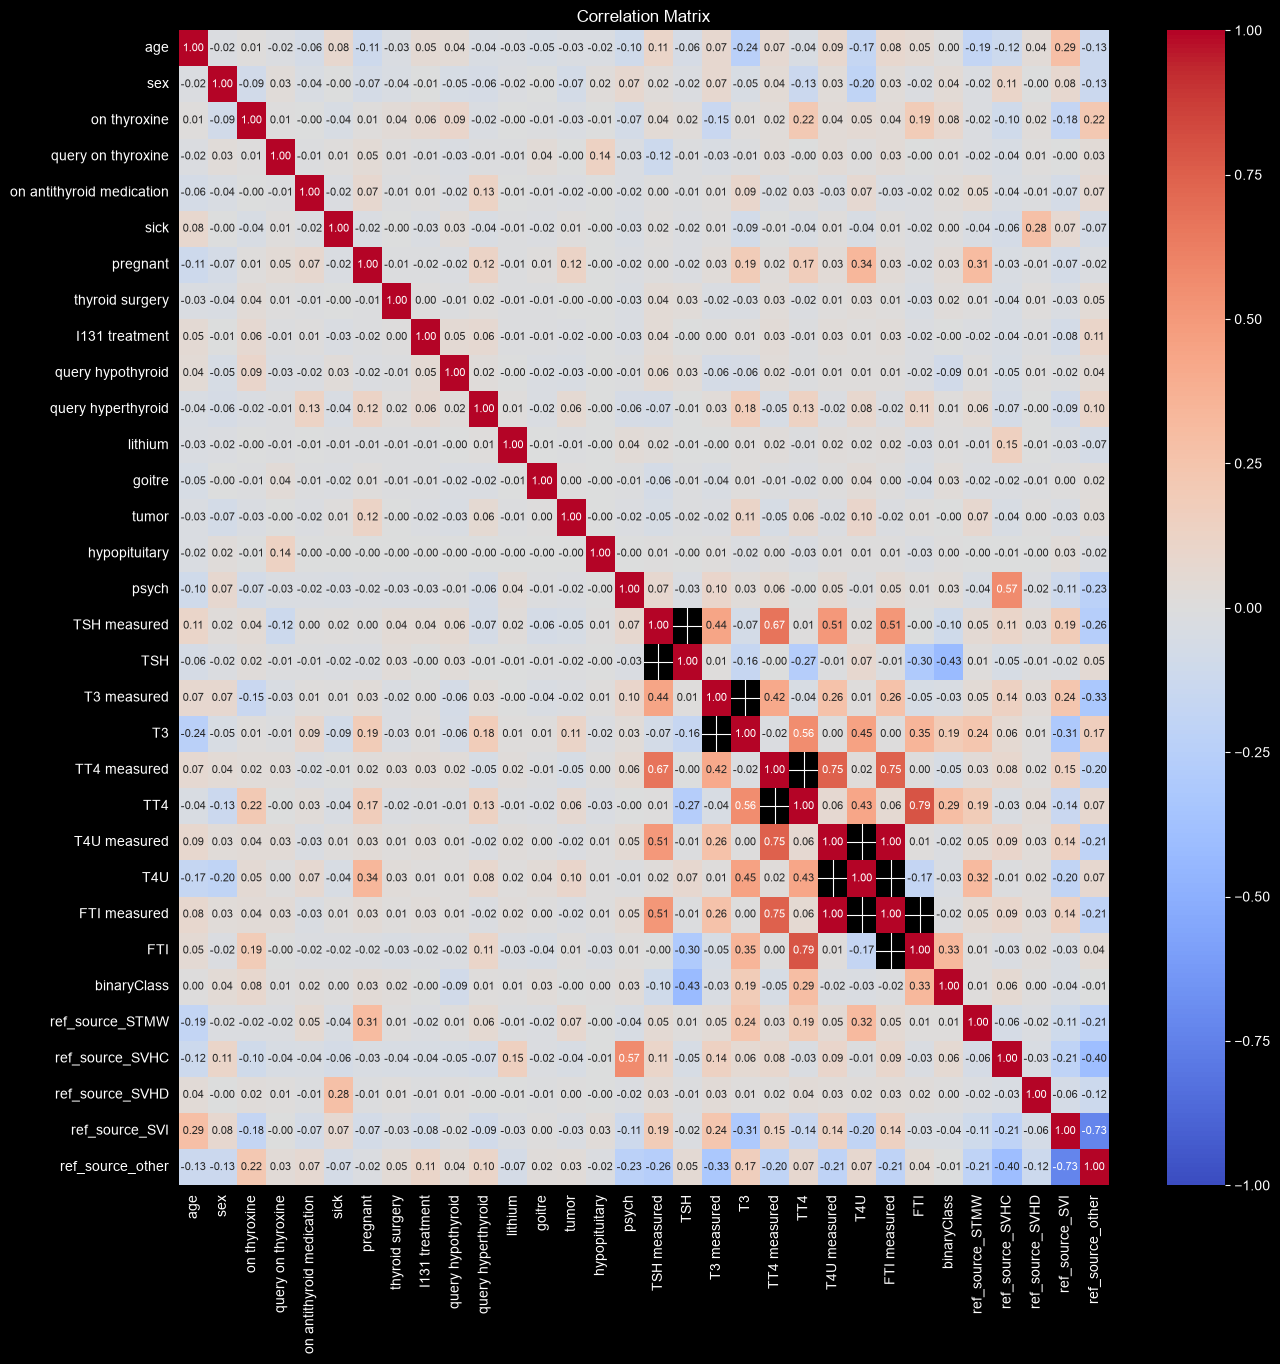

In [296]:
correlation_matrix = dados.select_dtypes(include=['number']).corr()

# plotar o mapa de calor da matriz de correlação
plt.figure(figsize=(15, 15))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, annot_kws={'size': 8}, fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

Após analisar a matriz de correlação, podemos perceber que as features mais fortes são:
- TSH_measured: -0.10
- TSH: -0.43
- T3: 0.19
- T4U: 0.32
- ref_source_SVHC: 0.06
- FTI: 0.33
- TT4: 0.29
- query hypothyroid: -0.09
- on thyroxine: 0.08
- TT4_measured: 0.05

Com isso, as decisões que foram feitas anteriormente sobre as variáveis, com as seguintes relações de valores nulos:
-T3: 20.38%
-TT4: 6.12%
-T4U: 10.25%
-FTI: 10.20

serão mudadas. Por serem variáveis com fortes influências, será retirado valores altos de outliers (definidos manualmente), e o restante dos valores outliers serão mantidos. Já os valores faltantes, serão substituídos pela média da feature. As features com correlação no intervalo -0.04 à 0.04 serão descartados. Portanto, não precisarão de tratamento

In [297]:
# TSH: retirando valores maiores que 400
variavel = 'TSH'
valor_selecionado = 400
dados.drop(dados[dados[variavel] > valor_selecionado].index, inplace=True)
dados[variavel] = dados[variavel].fillna(dados[variavel].mean())

# T3: retirando valores maiores que 7 e substituindo faltantes pela média
variavel = 'T3'
valor_selecionado = 7
dados.drop(dados[dados[variavel] > valor_selecionado].index, inplace=True)
dados[variavel] = dados[variavel].fillna(dados[variavel].mean())

# FTI: retirando valores maiores que 200 e substituindo faltantes pela média
variavel = 'FTI'
valor_selecionado = 200
dados.drop(dados[dados[variavel] > valor_selecionado].index, inplace=True)
dados[variavel] = dados[variavel].fillna(dados[variavel].mean())

# TT4: retirando valores maiores que 200 e substituindo faltantes pela média
variavel = 'TT4'
valor_selecionado = 200
dados.drop(dados[dados[variavel] > valor_selecionado].index, inplace=True)
dados[variavel] = dados[variavel].fillna(dados[variavel].mean())

# T4U: substituindo faltantes pela média
variavel = 'T4U'
dados[variavel] = dados[variavel].fillna(dados[variavel].mean())

In [298]:
# Retirando as features menos relevantes (fora do intervalo de correlação -0.04 à 0.04)
colunas_dropar = ['age', 'sex', 'query on thyroxine', 'on antithyroid medication','sick', 'pregnant','thyroid surgery', 'I131 treatment','query hypothyroid', 'lithium', 'goitre', 'tumor','hypopituitary','psych', 'T3 measured','T4U measured','FTI measured','ref_source_STMW','ref_source_SVHD','ref_source_SVI','ref_source_other']

dados = dados.drop(columns=colunas_dropar)

In [299]:
dados

,on thyroxine,query hyperthyroid,TSH measured,TSH,T3,TT4 measured,TT4,T4U,FTI,binaryClass,ref_source_SVHC
0,0,0,1,1.300000,2.500000,1,125.000000,1.140000,109.000000,1,1
1,0,0,1,4.100000,2.000000,1,102.000000,0.991127,108.318037,1,0
2,0,0,1,0.980000,2.002486,1,109.000000,0.910000,120.000000,1,0
3,1,0,1,0.160000,1.900000,1,175.000000,0.991127,108.318037,1,0
4,0,0,1,0.720000,1.200000,1,61.000000,0.870000,70.000000,1,0
...,...,...,...,...,...,...,...,...,...,...,...
3767,0,0,0,4.391485,2.002486,0,105.517955,0.991127,108.318037,1,0
3768,0,0,1,1.000000,2.100000,1,124.000000,1.080000,114.000000,1,0
3769,0,1,1,5.100000,1.800000,1,112.000000,1.070000,105.000000,1,0
3770,0,0,1,0.700000,2.000000,1,82.000000,0.940000,87.000000,1,0


Analisando a matriz de correlação de maneira mais objetiva, temos:

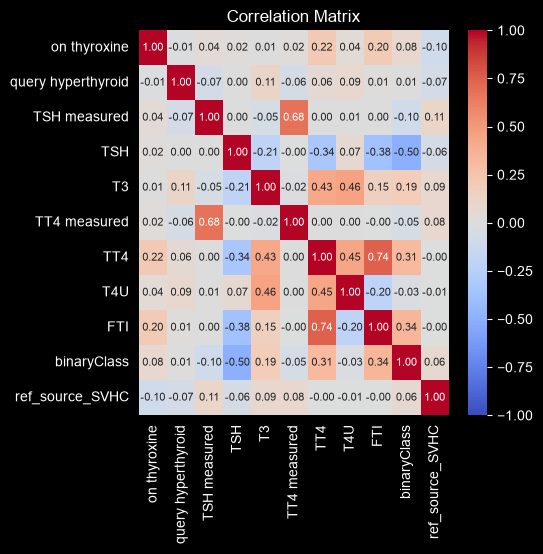

In [300]:
correlation_matrix = dados.select_dtypes(include=['number']).corr()

# plotar o mapa de calor da matriz de correlação
plt.figure(figsize=(5, 5))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, annot_kws={'size': 8}, fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

Houve mudança nos valores de correlação das features em realação ao conjunto completo da matriz anterior. Serão trabalhadas com essas 10 features para prever o binaryClass

# 5 - Divisão, Processamento e Tratamento dos dados

## 5.1 - Divisão de treino e teste

Nesta etapa, ocorrerá a divisão da base de teste e treino, o tratamento e a padronização dos dados

In [301]:
# Divisão dos dados
X = dados.drop('binaryClass', axis=1)
y = dados['binaryClass']

# Separação dos dados em treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 5.2 - Treinamento dos modelos sem Padronização, sem Balanceamento e sem Ajuste de Hiperpaâmetros

### Random Forest

In [302]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [303]:
# Inicialização do modelo Random Forest
random_forest = RandomForestClassifier(random_state=42)
random_forest.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [304]:
y_pred = random_forest.predict(X_test)

In [305]:
# Relatório
relatorio = classification_report(y_test, y_pred)
print('Relatório de Classificação: \n', relatorio)

Relatório de Classificação: 
               precision    recall  f1-score   support

           0       0.92      0.97      0.94        60
           1       1.00      0.99      0.99       675

    accuracy                           0.99       735
   macro avg       0.96      0.98      0.97       735
weighted avg       0.99      0.99      0.99       735



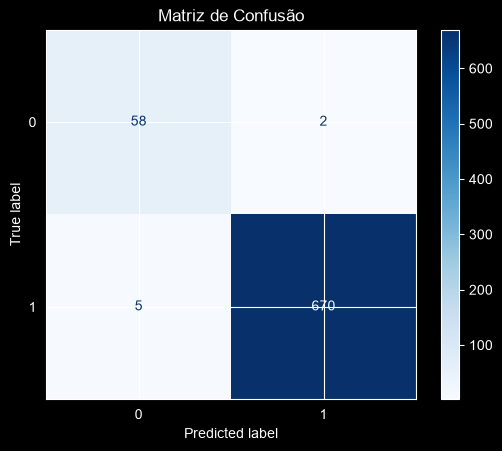

In [306]:
# Análise da Matriz de Confusão
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title('Matriz de Confusão')
plt.show()

O modelo Random Forest, mesmo sem padronização e ajuste de hiperparâmetros apresentou uma precisão de 100% para a classe 1, e falsos positivos baixíssimos

### SVM

In [307]:
from sklearn.svm import SVC

In [308]:
svm_model_linear = SVC(kernel='linear', C=1.0, random_state=42)
svm_model_linear.fit(X_train, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [309]:
y_pred = svm_model_linear.predict(X_test)

In [310]:
# Relatório
relatorio = classification_report(y_test, y_pred)
print('Relatório de Classificação: \n', relatorio)

Relatório de Classificação: 
               precision    recall  f1-score   support

           0       0.94      0.55      0.69        60
           1       0.96      1.00      0.98       675

    accuracy                           0.96       735
   macro avg       0.95      0.77      0.84       735
weighted avg       0.96      0.96      0.96       735



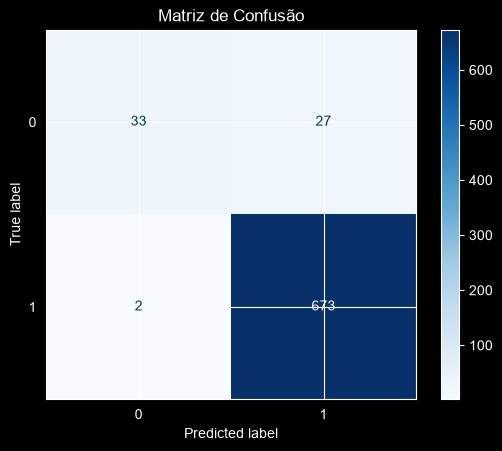

In [311]:
# Análise da Matriz de Confusão
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title('Matriz de Confusão')
plt.show()

O Recall do SVM foi de 100% para a classe 1, porém obteve 55% para a classe 0. Como o SVM é sensível à padronização e balanceamento, iremos tentar otimizar na etapa de balanceamento, padronização e ajuste de hiperparâmetros

### XGBoost

In [312]:
xgb_model = XGBClassifier(random_state=42)
xgb_model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [313]:
y_pred = xgb_model.predict(X_test)

In [314]:
# Relatório
relatorio = classification_report(y_test, y_pred)
print('Relatório de Classificação: \n', relatorio)

Relatório de Classificação: 
               precision    recall  f1-score   support

           0       0.91      0.98      0.94        60
           1       1.00      0.99      0.99       675

    accuracy                           0.99       735
   macro avg       0.95      0.99      0.97       735
weighted avg       0.99      0.99      0.99       735



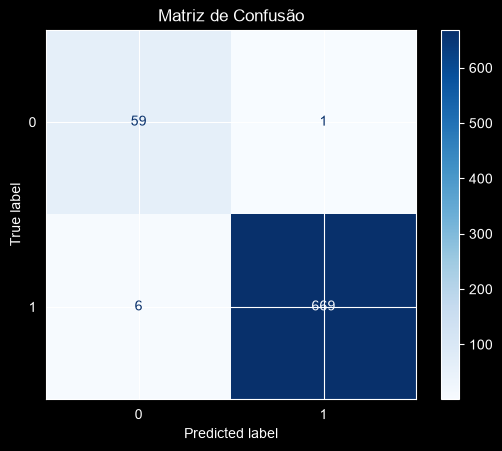

In [315]:
# Análise da Matriz de Confusão
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title('Matriz de Confusão')
plt.show()

O modelo XGBoost se mostrou mais robusto e consistente, como o recall de 98% para a classe 0 e 99% para a classe 1. A seguir, será feito o processo de balanceamento e padronização dos dados. E por último, além do balanceamento e padronização, será feito ajuste nos hiperparâmetros

## 5.3 - Treinamento do modelo com PADRONIZAÇÃO E BALANCEAMENTO, porém SEM AJUSTE DE HIPERPARÂMETROS

Será visualizado a quantidade de valores de 1 e 0 para a variável 'binaryClass'

In [316]:
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

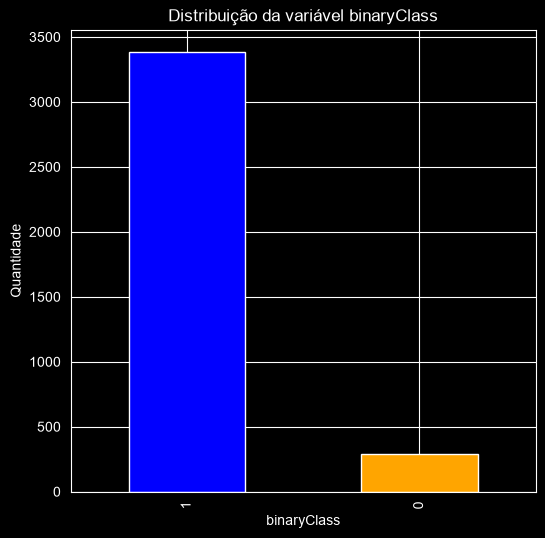

binaryClass
1    92.213449
0     7.786551
Name: proportion, dtype: float64


In [317]:
# Visualização gráfica da quantidade de valores da classe 'binaryClass'

# Contagem de cada classe do alvo
binary_class_counts = dados['binaryClass'].value_counts()

plt.figure(figsize=(6, 6))
binary_class_counts.plot(kind='bar', color=['blue', 'orange'])
plt.title('Distribuição da variável binaryClass')
plt.xlabel('binaryClass')
plt.ylabel('Quantidade')
plt.show()

# Proporção em %
print(dados['binaryClass'].value_counts(normalize=True)*100)

Percebe-se que há um desbalanceamento enorme. 92,21% dos dados são compostos por 1, e apenas 7,78% para a classe 0. Isso justifica o desempenho baixo do SVM para a classe 0

In [318]:
# Criação da instância do SMOTE
smote = SMOTE(random_state=42)

# Aplicando o SMOTE aos dados de treinamento
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

# Verificando a distribuição das calsses após o balanceamento
print('Distribução das classes após o balanceamento: ')
print(y_train_balanced.value_counts())
print(X_train_balanced.value_counts())

Distribução das classes após o balanceamento: 
binaryClass
1    2712
0    2712
Name: count, dtype: int64
on thyroxine  query hyperthyroid  TSH measured  TSH        T3        TT4 measured  TT4         T4U       FTI         ref_source_SVHC
0             0                   0             4.391485   2.002486  0             105.517955  0.991127  108.318037  0                  113
              1                   0             4.391485   2.002486  0             105.517955  0.991127  108.318037  0                   15
1             0                   0             4.391485   2.002486  0             105.517955  0.991127  108.318037  0                   11
0             0                   0             4.391485   2.200000  0             105.517955  0.991127  108.318037  0                    3
                                                           2.100000  0             105.517955  0.991127  108.318037  0                    3
                                                              

Agora, será feito a padronização dos dados

In [319]:
# Inicialização do StandardScaler
scaler = StandardScaler()

# Ajuste do treino e teste para a padronização
X_train_balanced_scaled = scaler.fit_transform(X_train_balanced)
X_test_balanced_scaled = scaler.transform(X_test)

### Random Forest

In [320]:
# Aplicando o treinamento aos dados balanceados
random_forest_balanced_scaled = RandomForestClassifier(random_state=42)
random_forest_balanced_scaled.fit(X_train_balanced_scaled, y_train_balanced)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [321]:
y_pred_balanced_scaled = random_forest_balanced_scaled.predict(X_test_balanced_scaled)

In [322]:
# Relatório
relatorio = classification_report(y_test, y_pred_balanced_scaled)
print('Relatório de Classificação: \n', relatorio)

Relatório de Classificação: 
               precision    recall  f1-score   support

           0       0.94      0.98      0.96        60
           1       1.00      0.99      1.00       675

    accuracy                           0.99       735
   macro avg       0.97      0.99      0.98       735
weighted avg       0.99      0.99      0.99       735



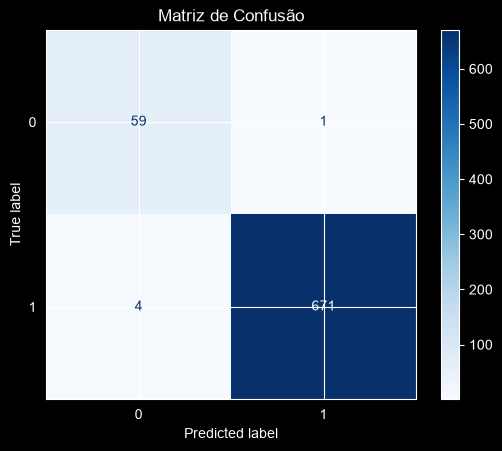

In [323]:
# Análise da Matriz de Confusão
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_balanced_scaled, cmap='Blues')
plt.title('Matriz de Confusão')
plt.show()

O Balanceamento e a Padronização mostraram uma leve melhora para o modelo, e reduziram os falsos negativos. Trazendo o recall altíssimo

### SVM

In [324]:
# Inicialização SVC
svm_model_linear_balanced_scaled = SVC(kernel='linear', C=1.0, random_state=42)

In [325]:
# Treinamento e predição
svm_model_linear_balanced_scaled.fit(X_train_balanced_scaled, y_train_balanced)
y_pred_balanced_scaled = svm_model_linear_balanced_scaled.predict(X_test_balanced_scaled)

In [326]:
# Relatório
relatorio = classification_report(y_test, y_pred_balanced_scaled)
print('Relatório de Classificação: \n', relatorio)

Relatório de Classificação: 
               precision    recall  f1-score   support

           0       0.76      0.97      0.85        60
           1       1.00      0.97      0.99       675

    accuracy                           0.97       735
   macro avg       0.88      0.97      0.92       735
weighted avg       0.98      0.97      0.97       735



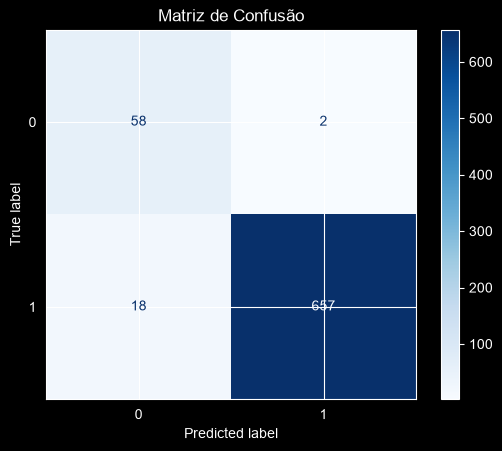

In [327]:
# Análise da Matriz de Confusão
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_balanced_scaled, cmap='Blues')
plt.title('Matriz de Confusão')
plt.show()

Nesse caso, o balanceamento e a padronização tiveram uma grande influência sobre o SVM, o recall melhorou muito para a classe 0, e a precisão também

### XGBoost

In [328]:
# Inicialização XGB
xgb_model_balanced_scaled = XGBClassifier(random_state=42)

In [329]:
#Treinamento e Predição
xgb_model_balanced_scaled.fit(X_train_balanced_scaled, y_train_balanced)
y_pred_balanced_scaled = xgb_model_balanced_scaled.predict(X_test_balanced_scaled)

In [330]:
# Relatório
relatorio = classification_report(y_test, y_pred_balanced_scaled)
print('Relatório de Classificação: \n', relatorio)

Relatório de Classificação: 
               precision    recall  f1-score   support

           0       0.91      0.98      0.94        60
           1       1.00      0.99      0.99       675

    accuracy                           0.99       735
   macro avg       0.95      0.99      0.97       735
weighted avg       0.99      0.99      0.99       735



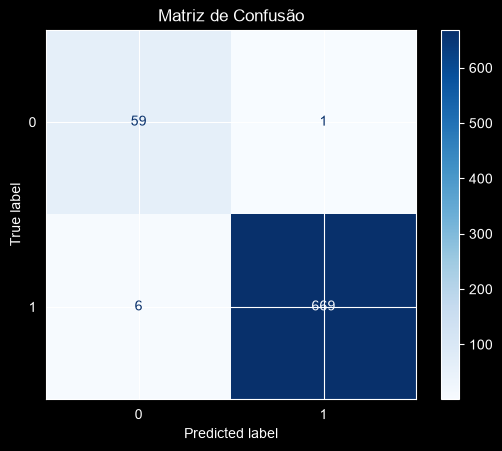

In [331]:
# Análise da Matriz de Confusão
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_balanced_scaled, cmap='Blues')
plt.title('Matriz de Confusão')
plt.show()

O modelo XGBoost manteve o desempenho. A etapa de padronização e balanceamento não causa melhora no modelo

## 5.4 - Ajuste de Hiperparâmetros

### Random Forest

In [332]:
# Inicialização Random Forest
random_forest_hiperparametros = RandomForestClassifier(random_state=42)

In [333]:
best_params = {
    'n_estimators': [100,200,500],
    'criterion': ['gini', 'entropy'],
    'max_features': ['auto', 'sqrt', 'log2'],
    'max_depth': [None, 10,20,40],
    'min_samples_split': [2, 5, 10]
}

In [334]:
grid_search = GridSearchCV(
    estimator=random_forest_balanced_scaled,
    param_grid=best_params,
    n_jobs=-1,
    scoring='precision',
    cv=5,
)

In [335]:
grid_search.fit(X_train_balanced_scaled, y_train_balanced)

C:\Users\joaom\PycharmProjects\MODULO_43\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
360 fits failed out of a total of 1080.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
211 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\joaom\PycharmProjects\MODULO_43\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\joaom\PycharmProjects\MODULO_43\.venv\Lib\site-packages\sklearn\base.py", line 1393, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "C:\Users\joaom\PycharmPro

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [None, 10, ...], 'max_features': ['auto', 'sqrt', ...], 'min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for call

In [336]:
best_params_encontrados = grid_search.best_params_
print('Melhores Parâmetros encontrados: \n', best_params_encontrados)

Melhores Parâmetros encontrados: 
 {'criterion': 'entropy', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 500}


In [337]:
y_pred_hiperparametros = grid_search.predict(X_test_balanced_scaled)

In [338]:
# Relatório
relatorio = classification_report(y_test, y_pred_hiperparametros)
print('Relatório de Classificação: \n', relatorio)

Relatório de Classificação: 
               precision    recall  f1-score   support

           0       0.94      0.98      0.96        60
           1       1.00      0.99      1.00       675

    accuracy                           0.99       735
   macro avg       0.97      0.99      0.98       735
weighted avg       0.99      0.99      0.99       735



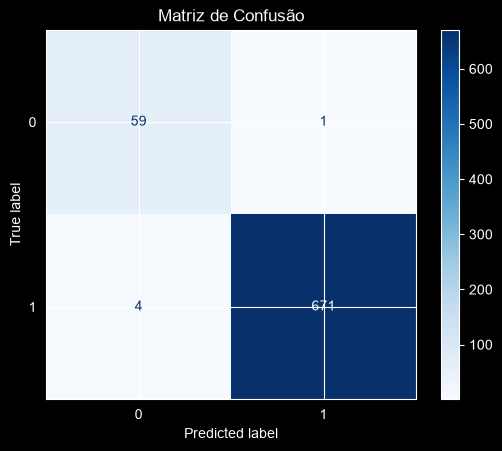

In [339]:
# Análise da Matriz de Confusão
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_hiperparametros, cmap='Blues')
plt.title('Matriz de Confusão')
plt.show()

Diminuição dos falsos negativos e falsos positivos

### SVM

In [340]:
# Inicialização SVM
svm_hiperparametros = SVC(random_state=42)

In [341]:
best_params = {
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'degree': [2,3,4],
    'C': [0.01, 0.1, 1]
}

In [342]:
grid_search_svm = GridSearchCV(
    estimator=svm_hiperparametros,
    param_grid=best_params,
    n_jobs=-1,
    scoring='precision',
    cv=5
)


In [343]:
grid_search_svm.fit(X_train_balanced_scaled, y_train_balanced)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(random_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.01, 0.1, ...], 'degree': [2, 3, ...], 'kernel': ['linear', 'poly', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosi

In [344]:
best_params_encontrados = grid_search_svm.best_params_
print('Melhores parâmetros encontrados: \n', best_params_encontrados)

Melhores parâmetros encontrados: 
 {'C': 1, 'degree': 2, 'kernel': 'linear'}


In [345]:
y_pred_hiperparametros = grid_search_svm.predict(X_test_balanced_scaled)

In [346]:
# Relatório
relatorio = classification_report(y_test, y_pred_hiperparametros)
print('Relatório de Classificação: \n', relatorio)

Relatório de Classificação: 
               precision    recall  f1-score   support

           0       0.76      0.97      0.85        60
           1       1.00      0.97      0.99       675

    accuracy                           0.97       735
   macro avg       0.88      0.97      0.92       735
weighted avg       0.98      0.97      0.97       735



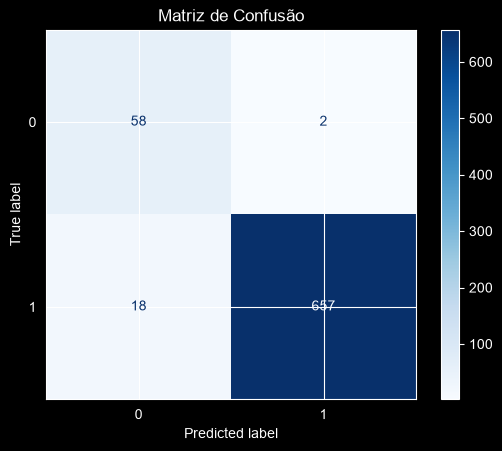

In [347]:
# Análise da Matriz de Confusão
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_hiperparametros, cmap='Blues')
plt.title('Matriz de Confusão')
plt.show()

Não houve tanta melhora

### XGBoost

In [348]:
#Inicialização XGB
xgb_model_hiperparametros = XGBClassifier(random_state=42)

In [349]:
best_params = {
    'n_estimators': [100,200,500],
    'max_depth': [None, 10,20,40],
    'subsample': [0.6, 0.8, 1.0],
    'learning_rate': [0.01, 0.05, 0.1]
}

In [350]:
grid_search_xgb = GridSearchCV(
    estimator=xgb_model_hiperparametros,
    param_grid=best_params,
    cv=5,
    n_jobs=-1,
    scoring='precision',
)

In [351]:
grid_search_xgb.fit(X_train_balanced_scaled, y_train_balanced)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.01, 0.05, ...], 'max_depth': [None, 10, ...], 'n_estimators': [100, 200, ...], 'subsample': [0.6, 0.8, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.

In [352]:
best_params_encontrados = grid_search_xgb.best_params_
print('Melhores parâmetros encontrados: \n', best_params_encontrados)

Melhores parâmetros encontrados: 
 {'learning_rate': 0.1, 'max_depth': None, 'n_estimators': 500, 'subsample': 1.0}


In [353]:
y_pred_hiperparametros = grid_search_xgb.predict(X_test_balanced_scaled)

In [354]:
# Relatório
relatorio = classification_report(y_test, y_pred_hiperparametros)
print('Relatório de Classificação: \n', relatorio)

Relatório de Classificação: 
               precision    recall  f1-score   support

           0       0.91      0.98      0.94        60
           1       1.00      0.99      0.99       675

    accuracy                           0.99       735
   macro avg       0.95      0.99      0.97       735
weighted avg       0.99      0.99      0.99       735



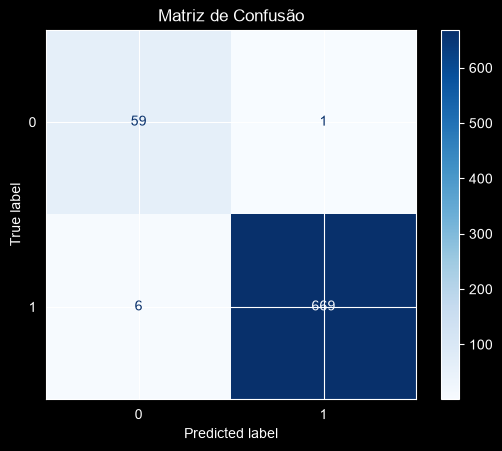

In [355]:
# Análise da Matriz de Confusão
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_hiperparametros, cmap='Blues')
plt.title('Matriz de Confusão')
plt.show()

Diminuição dos falsos negativos

# 6 - Conclusões

## Comparativo dos modelos

Base de teste: 735 registros, sendo 60 com hipertireoidismo (classe 0) e 675 negativos (classe 1).

| Cenário | Modelo | Acurácia | Precisão (hiper.) | Recall (hiper.) | F1 (hiper.) | Falsos negativos | Falsos positivos |
|:--|:--|--:|--:|--:|--:|--:|--:|
| 1. Puro | Random Forest | 0,99 | 0,92 | 0,97 | 0,94 | 2 | 5 |
| 1. Puro | SVM | 0,96 | 0,94 | 0,55 | 0,69 | 27 | 2 |
| 1. Puro | XGBoost | 0,99 | 0,91 | 0,98 | 0,94 | 1 | 6 |
| 2. Padronização + SMOTE | **Random Forest** | **0,99** | **0,94** | **0,98** | **0,96** | **1** | **4** |
| 2. Padronização + SMOTE | SVM | 0,97 | 0,76 | 0,97 | 0,85 | 2 | 18 |
| 2. Padronização + SMOTE | XGBoost | 0,99 | 0,91 | 0,98 | 0,94 | 1 | 6 |
| 3. Padronização + SMOTE + Grid Search | Random Forest | 0,99 | 0,94 | 0,98 | 0,96 | 1 | 4 |
| 3. Padronização + SMOTE + Grid Search | SVM | 0,97 | 0,76 | 0,97 | 0,85 | 2 | 18 |
| 3. Padronização + SMOTE + Grid Search | XGBoost | 0,99 | 0,91 | 0,98 | 0,94 | 1 | 6 |

*Falso negativo: paciente com hipertireoidismo classificado como negativo. Falso positivo: paciente negativo classificado como hipertireoidismo.*

## Conclusão

**Modelo recomendado: Random Forest com padronização e balanceamento (cenário 2).** É o que melhor atende, simultaneamente, aos três critérios do cliente:

1. **Minimizar falsos negativos:** deixou passar apenas 1 caso de hipertireoidismo em 60 (recall de 0,98), empatado com o XGBoost e à frente do SVM.
2. **Boa precisão:** 0,94, a maior entre os três modelos. Dos 675 pacientes negativos, apenas 4 receberam um alarme falso, contra 6 do XGBoost e 18 do SVM.
3. **Robustez:** o desempenho praticamente não mudou entre os cenários (recall de 0,97 a 0,98 em todos), mostrando que o modelo é pouco sensível a pré-processamento e hiperparâmetros. Os parâmetros foram validados com validação cruzada de 5 folds.

**Por que a acurácia não foi o critério de escolha.** Com 92 % da base composta por negativos, um modelo que classificasse todos os pacientes como negativos teria 0,92 de acurácia e 60 falsos negativos. Em um problema de triagem clínica, o que importa é não deixar passar o doente. Por isso a comparação se concentrou no recall e na precisão da classe hipertireoidismo.

**O que o pré-processamento mudou.** Para o SVM, padronização e SMOTE foram decisivos: os falsos negativos caíram de 27 para 2. O custo foi a precisão, que caiu de 0,94 para 0,76, ou seja, o modelo passou a acertar os doentes à custa de 18 alarmes falsos. Para Random Forest e XGBoost, modelos baseados em árvores, o efeito foi marginal, como esperado, já que árvores não dependem da escala das variáveis.

**O que o ajuste de hiperparâmetros mudou.** Nada, em nenhum dos três modelos. Os parâmetros padrão já estavam no teto de desempenho desta base. O resultado é informativo: o limite está nos dados, não no ajuste do modelo.

**Random Forest × XGBoost.** Os dois empatam nos falsos negativos (1 caso). O desempate é a precisão: com o mesmo recall, o Random Forest gera menos exames desnecessários.